# Bank Loan Analysis - Python

A simple look at the loan data with pandas and a few charts.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## Load the data

In [2]:
df = pd.read_csv("../financial_loan.csv")
df.head()

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,2/11/2021,9/13/2021,4/13/2021,...,C4,60 months,Source Verified,30000.0,0.0100,59.83,0.1527,2500,4,1009
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,1/1/2021,12/14/2021,1/15/2021,...,E1,36 months,Source Verified,48000.0,0.0535,109.43,0.1864,3000,4,3939
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,1/5/2021,12/12/2021,1/9/2021,...,C5,36 months,Not Verified,50000.0,0.2088,421.65,0.1596,12000,11,3522
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,2/25/2021,12/12/2021,3/12/2021,...,B2,60 months,Source Verified,42000.0,0.0540,97.06,0.1065,4500,9,4911
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,1/1/2021,12/14/2021,1/15/2021,...,A1,36 months,Verified,83000.0,0.0231,106.53,0.0603,3500,28,3835


In [3]:
df.shape

(38576, 24)

In [4]:
df.isnull().sum()

id                          0
address_state               0
application_type            0
emp_length                  0
emp_title                1438
grade                       0
home_ownership              0
issue_date                  0
last_credit_pull_date       0
last_payment_date           0
loan_status                 0
next_payment_date           0
member_id                   0
purpose                     0
sub_grade                   0
term                        0
verification_status         0
annual_income               0
dti                         0
installment                 0
int_rate                    0
loan_amount                 0
total_acc                   0
total_payment               0
dtype: int64

## Clean up

Convert the issue date from text to a proper date.

In [5]:
df["issue_date"] = pd.to_datetime(df["issue_date"], format="%m/%d/%Y")

## Main numbers

In [6]:
print("Total applications:", len(df))
print("Total funded:", df["loan_amount"].sum())
print("Total received:", df["total_payment"].sum())
print("Average interest rate:", round(df["int_rate"].mean() * 100, 2))
print("Average DTI:", round(df["dti"].mean() * 100, 2))

Total applications: 38576
Total funded: 435757075
Total received: 473070933
Average interest rate: 12.05
Average DTI: 13.33


## Good vs bad loans

Fully Paid and Current are good loans. Charged Off is a bad loan.

In [7]:
bad_loans = df[df["loan_status"] == "Charged Off"]
good_loans = df[df["loan_status"] != "Charged Off"]

print("Good loans:", len(good_loans))
print("Bad loans:", len(bad_loans))
print("Bad loan %:", round(len(bad_loans) / len(df) * 100, 2))

Good loans: 33243
Bad loans: 5333
Bad loan %: 13.82


In [8]:
print("Bad loans funded:", bad_loans["loan_amount"].sum())
print("Bad loans received:", bad_loans["total_payment"].sum())
print("Money not recovered:", bad_loans["loan_amount"].sum() - bad_loans["total_payment"].sum())

Bad loans funded: 65532225
Bad loans received: 37284763
Money not recovered: 28247462


## Loan status breakdown

In [9]:
df["loan_status"].value_counts()

loan_status
Fully Paid     32145
Charged Off     5333
Current         1098
Name: count, dtype: int64

In [10]:
df.groupby("loan_status")[["loan_amount", "total_payment"]].sum()

,loan_amount,total_payment
loan_status,,
Charged Off,65532225,37284763
Current,18866500,24199914
Fully Paid,351358350,411586256


In [11]:
df.groupby("loan_status")["int_rate"].mean() * 100

loan_status
Charged Off    13.878575
Current        15.099326
Fully Paid     11.641071
Name: int_rate, dtype: float64

## Charts

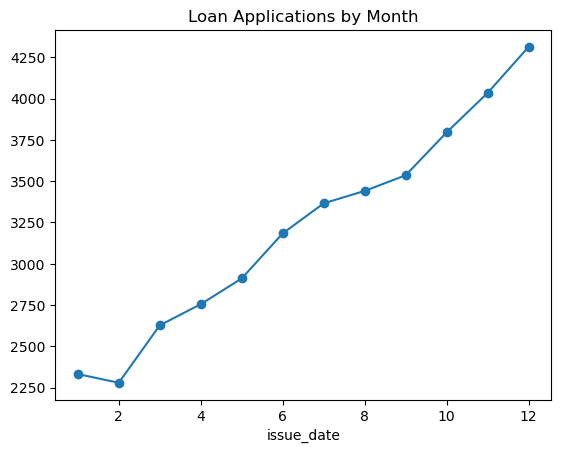

In [12]:
monthly = df.groupby(df["issue_date"].dt.month)["id"].count()
monthly.plot(kind="line", marker="o", title="Loan Applications by Month")
plt.show()

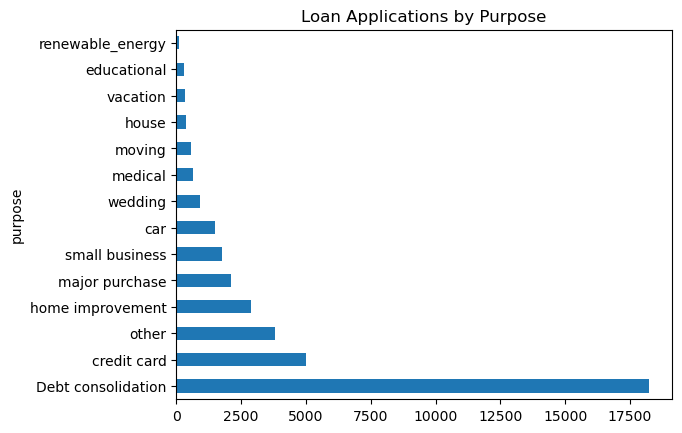

In [13]:
df["purpose"].value_counts().plot(kind="barh", title="Loan Applications by Purpose")
plt.show()

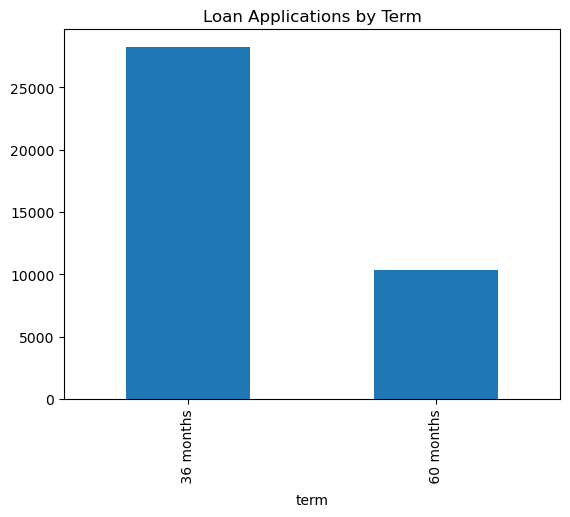

In [14]:
df["term"].value_counts().plot(kind="bar", title="Loan Applications by Term")
plt.show()

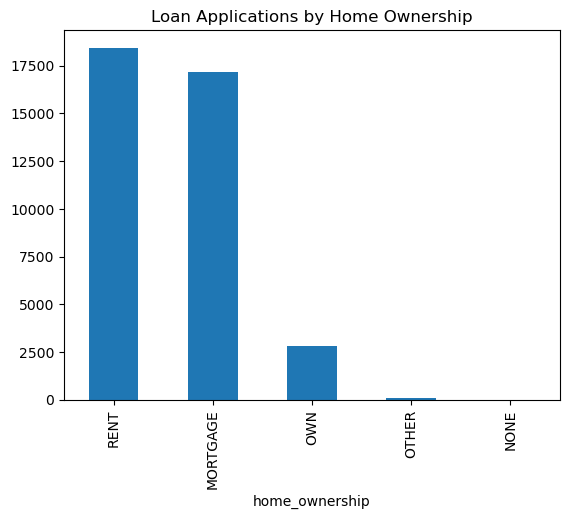

In [15]:
df["home_ownership"].value_counts().plot(kind="bar", title="Loan Applications by Home Ownership")
plt.show()

## Takeaways

- About 1 in 7 loans (13.82%) ends up charged off.
- Charged-off loans have a higher average interest rate than fully paid ones.
- Debt consolidation is by far the most common loan purpose.
- Most borrowers choose 36-month loans over 60-month loans.